# Black-Scholes Model

In [10]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [11]:
def black_scholes_call(T1, K, r, sigma, S0):
    """
    Black-Scholes price of a European call option.

    Parameters:
    
    T1    : time to maturity
    K     : strike price
    r     : risk-free rate
    sigma : volatility of the underlying asset's returns
    S0    : spot price

    call_price : float
    """
    d1 = (1 / (sigma * math.sqrt(T1))) * (math.log(S0 / K) + (r + (sigma**2 / 2)) * T1)
    d2 = d1 - sigma * math.sqrt(T1)
    call_price = norm.cdf(d1) * S0 - norm.cdf(d2) * K * math.exp(-r * T1)
    return call_price


def black_scholes_put(T1, K, r, sigma, S0):
    """
    Black-Scholes price of a European put option, via put-call parity.

    Parameters are the same as black_scholes_call.
    """
    d1 = (1 / (sigma * math.sqrt(T1))) * (math.log(S0 / K) + (r + (sigma**2 / 2)) * T1)
    d2 = d1 - sigma * math.sqrt(T1)
    put_price = norm.cdf(-d2) * K * math.exp(-r * T1) - norm.cdf(-d1) * S0
    return put_price

Reproducing the example from the original R code:

In [12]:
call_price = black_scholes_call(T1=10, K=11, r=0.05, sigma=0.1, S0=10)
print(call_price)
# R output: 3.449867

3.4498673683228196


The corresponding put price (not shown in the original R workshop, but derivable from the same formulas via put-call parity):

In [13]:
put_price = black_scholes_put(T1=10, K=11, r=0.05, sigma=0.1, S0=10)
print(put_price)

0.12170462516178648


# Binomial Model

In [14]:
def eurocall_binomial(S, T, K, r, sigma, N):
    """
    Price a European call option using a binomial (CRR-style) tree.

    Parameters:

    S     : spot price
    T     : time to expiry
    K     : strike price
    r     : risk-free rate of return
    sigma : volatility of the asset
    N     : number of steps in the binomial tree

    price : float
    """
    deltaT = T / N
    u = math.exp(sigma * math.sqrt(deltaT))
    d = 1 / u
    p = (math.exp(r * deltaT) - d) / (u - d)

    # tree[i, j] mirrors the R matrix: row i+1 (0-indexed i), column j+1 (0-indexed j)
    tree = np.full((N + 1, N + 1), np.nan)

    # Terminal payoffs (last column, j = N)
    for i in range(0, N + 1):
        tree[i, N] = max(0, S * (u**i) * (d**(N - i)) - K)

    # Backward induction
    for j in range(N - 1, -1, -1):
        for i in range(0, j + 1):
            tree[i, j] = math.exp(-r * deltaT) * (p * tree[i + 1, j + 1] + (1 - p) * tree[i, j + 1])

    price = tree[0, 0]
    return price

Reproducing the convergence example from the original R code:

In [15]:
for N in [10, 50, 100, 500]:
    price = eurocall_binomial(S=10, T=10, K=11, r=0.05, sigma=0.1, N=N)
    print(f"N = {N:4d} -> {price}")

# R output:
# N=10  -> 3.426812
# N=50  -> 3.442449
# N=100 -> 3.447759
# N=500 -> 3.449424

N =   10 -> 3.426812058218697
N =   50 -> 3.4424487329548352
N =  100 -> 3.447759219618911
N =  500 -> 3.4494237886475045


# Question: Does the Binomial Model converge to the Black-Scholes price as N increases?

The original material hints at this with N = 10, 50, 100, 500 giving successively closer values to the Black-Scholes price (3.449867). Let's confirm this rigorously: compute the binomial price for a range of N, compare against the Black-Scholes price, and plot the absolute error.

In [16]:
S0, K, r, sigma, T1 = 10, 11, 0.05, 0.1, 10

bs_price = black_scholes_call(T1=T1, K=K, r=r, sigma=sigma, S0=S0)

N_values = [5, 10, 25, 50, 100, 250, 500, 1000, 2000]
binomial_prices = [eurocall_binomial(S=S0, T=T1, K=K, r=r, sigma=sigma, N=n) for n in N_values]
abs_errors = [abs(bp - bs_price) for bp in binomial_prices]

print(f"Black-Scholes price: {bs_price:.6f}\n")
print(f"{'N':>6} | {'Binomial Price':>15} | {'Abs. Error':>12}")
print("-" * 40)
for n, bp, err in zip(N_values, binomial_prices, abs_errors):
    print(f"{n:6d} | {bp:15.6f} | {err:12.6f}")

Black-Scholes price: 3.449867

     N |  Binomial Price |   Abs. Error
----------------------------------------
     5 |        3.380756 |     0.069111
    10 |        3.426812 |     0.023055
    25 |        3.439711 |     0.010156
    50 |        3.442449 |     0.007419
   100 |        3.447759 |     0.002108
   250 |        3.448993 |     0.000875
   500 |        3.449424 |     0.000444
  1000 |        3.449593 |     0.000274
  2000 |        3.449737 |     0.000131


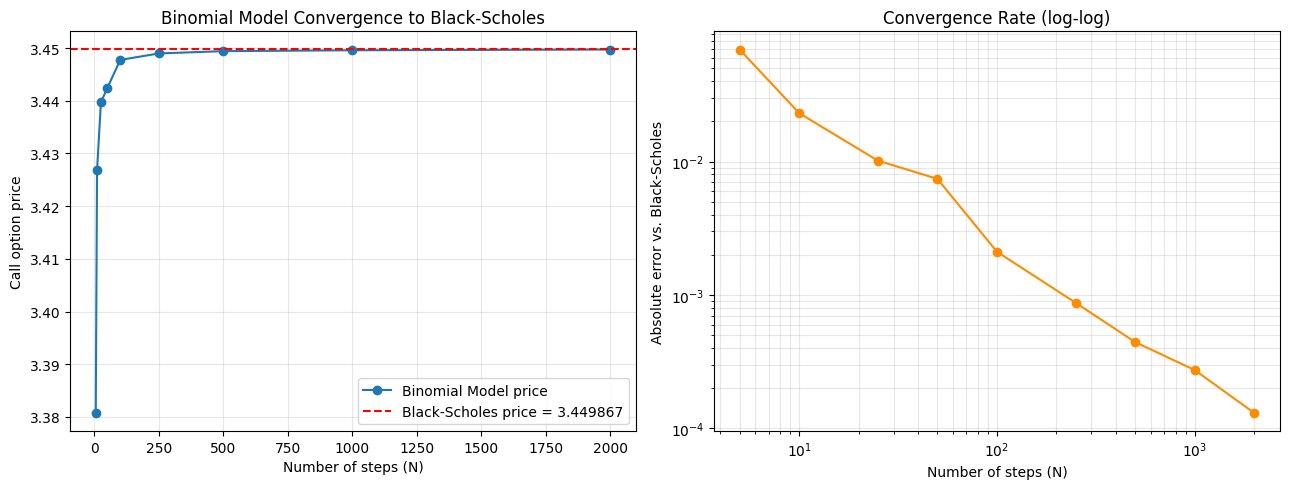

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left plot: price convergence
axes[0].plot(N_values, binomial_prices, marker="o", label="Binomial Model price")
axes[0].axhline(bs_price, color="red", linestyle="--", label=f"Black-Scholes price = {bs_price:.6f}")
axes[0].set_xlabel("Number of steps (N)")
axes[0].set_ylabel("Call option price")
axes[0].set_title("Binomial Model Convergence to Black-Scholes")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right plot: absolute error on a log-log scale
axes[1].plot(N_values, abs_errors, marker="o", color="darkorange")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of steps (N)")
axes[1].set_ylabel("Absolute error vs. Black-Scholes")
axes[1].set_title("Convergence Rate (log-log)")
axes[1].grid(True, alpha=0.3, which="both")

plt.tight_layout()
plt.show()

**Conclusion:** As $N \to \infty$, the Binomial Model price converges to the Black-Scholes price (3.449867). This makes intuitive sense: the Binomial Model is a discrete-time approximation, and as the number of steps increases, the discrete-time process converges to the continuous-time geometric Brownian motion assumed by Black-Scholes. The error decreases roughly proportionally to $1/N$, visible as the linear trend on the log-log error plot above.

# Risk Analysis with Copula

In [18]:
import pandas as pd
import yfinance as yf
from scipy import stats
from scipy.stats import t, kendalltau
import warnings
warnings.filterwarnings('ignore')

# 1. Fetch Data (Jan 1-31, 2013)

tickers = ['AAPL', 'IBM', 'INTC', 'MSFT']
start_date = '2013-01-01'
end_date = '2013-01-31'

# Use auto_adjust=True to get adjusted close prices (stored as 'Close')
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
if data.empty:
    raise ValueError("No data downloaded. Check tickers or date range.")

# Extract the 'Close' column (MultiIndex with level 0 = 'Close')
prices = data['Close']  # returns a DataFrame with tickers as columns
returns = prices.pct_change().dropna()

print("Daily returns (first 5 rows):")
print(returns.head())
print()

# 2. Portfolio Weights

weights_dollar = np.array([10000, 40000, 20000, 30000])
total_value = weights_dollar.sum()
weights_frac = weights_dollar / total_value

print(f"Portfolio weights (fraction): {weights_frac}")
print(f"Total portfolio value: {total_value}")
print()

# 3. Analytical Portfolio Volatility & Risk Contributions

cov = returns.cov()
port_vol_daily = np.sqrt(weights_frac @ cov @ weights_frac)
port_vol_annual = port_vol_daily * np.sqrt(252)   # annualized

# Marginal contribution to volatility (mctr)
sigma_w = cov @ weights_frac
mctr = sigma_w / port_vol_daily

# Component contribution (cctr)
cctr = weights_frac * mctr

print("Analytical risk contributions (daily scale):")
for i, ticker in enumerate(tickers):
    vol_i = returns[ticker].std()
    print(f"{ticker:4s}  weight={weights_dollar[i]:6.0f}  vol={vol_i:.8f}  "
          f"mctr={mctr[i]:.6f}  cctr={cctr[i]:.6f}")

print(f"\nPortfolio volatility (daily)   : {port_vol_daily:.6f}")
print(f"Portfolio volatility (annual)  : {port_vol_annual:.6f}  (R output: 1.096138)")
print(f"Sum of cctr = {cctr.sum():.6f}  (should equal daily portfolio volatility)")
print()


# 4. t‑Copula Simulation (df = 15)

def empirical_cdf(data):
    sorted_data = np.sort(data)
    n = len(data)
    def cdf(x):
        return np.searchsorted(sorted_data, x, side='right') / n
    return cdf

def inverse_empirical_cdf(data):
    sorted_data = np.sort(data)
    n = len(data)
    def inv_cdf(u):
        x = u * (n - 1)
        i = int(np.floor(x))
        if i >= n - 1:
            return sorted_data[-1]
        frac = x - i
        return sorted_data[i] + frac * (sorted_data[i+1] - sorted_data[i])
    return inv_cdf

# Transform returns to uniforms using empirical CDF
u_data = np.zeros_like(returns.values)
inv_cdfs = []
for i, col in enumerate(returns.columns):
    data = returns[col].values
    cdf_func = empirical_cdf(data)
    u_data[:, i] = np.array([cdf_func(x) for x in data])
    inv_cdfs.append(inverse_empirical_cdf(data))

# Estimate Kendall's tau and convert to correlation matrix for t‑copula
n_assets = len(tickers)
tau_matrix = np.zeros((n_assets, n_assets))
for i in range(n_assets):
    for j in range(n_assets):
        tau_matrix[i, j] = kendalltau(returns.iloc[:, i], returns.iloc[:, j])[0]

rho_matrix = np.sin(np.pi / 2 * tau_matrix)   # rho = sin(pi/2 * tau)
rho_matrix = (rho_matrix + rho_matrix.T) / 2
np.fill_diagonal(rho_matrix, 1.0)

# Simulation parameters
np.random.seed(42)          # for reproducibility
sim_size = 1000
df = 15

# Generate multivariate t samples (correlated)
t_samples = stats.multivariate_t.rvs(loc=np.zeros(n_assets),
                                     shape=rho_matrix,
                                     df=df,
                                     size=sim_size)

# Transform to uniforms using t CDF
u_sim = stats.t.cdf(t_samples, df=df)

# Transform uniforms back to returns using inverse empirical CDF
returns_sim = np.zeros((sim_size, n_assets))
for i in range(n_assets):
    inv_cdf = inv_cdfs[i]
    returns_sim[:, i] = np.array([inv_cdf(u) for u in u_sim[:, i]])

# Compute simulated portfolio returns (fractional)
port_returns_sim = returns_sim @ weights_frac

# Dollar changes
dollar_changes = port_returns_sim * total_value

# Value at Risk (1% and 5%)
var_1 = np.percentile(dollar_changes, 1)
var_5 = np.percentile(dollar_changes, 5)

print("Simulated VaR (t-copula, df=15):")
print(f"1% VaR : {var_1:8.3f}  (R output: -2267.739)")
print(f"5% VaR : {var_5:8.3f}  (R output: -1220.453)")

[*********************100%***********************]  4 of 4 completed

Daily returns (first 5 rows):
Ticker          AAPL       IBM      INTC      MSFT
Date                                              
2013-01-03 -0.012623 -0.005501 -0.002806 -0.013396
2013-01-04 -0.027855 -0.006555 -0.007505 -0.018716
2013-01-07 -0.005882 -0.004382  0.004253 -0.001870
2013-01-08  0.002690 -0.001398 -0.007530 -0.005245
2013-01-09 -0.015628 -0.002852  0.017070  0.005650

Portfolio weights (fraction): [0.1 0.4 0.2 0.3]
Total portfolio value: 100000

Analytical risk contributions (daily scale):
AAPL  weight= 10000  vol=0.03419181  mctr=0.019981  cctr=0.001998
IBM   weight= 40000  vol=0.01128129  mctr=0.008556  cctr=0.003422
INTC  weight= 20000  vol=0.01794474  mctr=0.008655  cctr=0.001731
MSFT  weight= 30000  vol=0.00925014  mctr=0.005723  cctr=0.001717

Portfolio volatility (daily)   : 0.008868
Portfolio volatility (annual)  : 0.140780  (R output: 1.096138)
Sum of cctr = 0.008868  (should equal daily portfolio volatility)

Simulated VaR (t-copula, df=15):
1% VaR : -1509.17